In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("novagen_dataset.csv")

In [4]:
df.head().dtypes

Age                      float64
BMI                      float64
Blood_Pressure           float64
Cholesterol              float64
Glucose_Level            float64
Heart_Rate               float64
Sleep_Hours              float64
Exercise_Hours           float64
Water_Intake             float64
Stress_Level             float64
Target                     int64
Smoking                    int64
Alcohol                    int64
Diet                       int64
MentalHealth               int64
PhysicalActivity           int64
MedicalHistory             int64
Allergies                  int64
Diet_Type__Vegan            bool
Diet_Type__Vegetarian       bool
Blood_Group_AB              bool
Blood_Group_B               bool
Blood_Group_O               bool
dtype: object

In [5]:
# Data Coversion From Categorical to Numerical

# for binary class - astype(int)

#df["Diet_Type__Vegan"] = df["Diet_Type__Vegan"].astype(int)

# for boolean if string we have to use "True":1 and "False":0 (string )

df["Diet_Type__Vegan"] = df["Diet_Type__Vegan"].map( { True:1, False:0})
df["Diet_Type__Vegetarian"] = df["Diet_Type__Vegetarian"].map( { True:1, False:0})

# we can map each col separately

cols = [

    "Blood_Group_B",
    "Blood_Group_AB",
    "Blood_Group_O"
]

df[cols] = df[cols].astype(int)


In [6]:
df.head()

,Age,BMI,Blood_Pressure,Cholesterol,Glucose_Level,Heart_Rate,Sleep_Hours,Exercise_Hours,Water_Intake,Stress_Level,...,Diet,MentalHealth,PhysicalActivity,MedicalHistory,Allergies,Diet_Type__Vegan,Diet_Type__Vegetarian,Blood_Group_AB,Blood_Group_B,Blood_Group_O
0,2.0,26.0,111.0,198.0,99.0,72.0,4.0,1.0,5.0,5.0,...,1,2,1,0,1,0,1,1,0,0
1,8.0,24.0,121.0,199.0,103.0,75.0,2.0,1.0,2.0,9.0,...,1,2,1,2,2,0,0,1,0,0
2,81.0,27.0,147.0,203.0,100.0,74.0,10.0,-0.0,5.0,1.0,...,2,0,0,1,0,1,0,0,0,0
3,25.0,21.0,150.0,199.0,102.0,70.0,7.0,3.0,3.0,3.0,...,1,2,1,2,0,1,0,0,1,0
4,24.0,26.0,146.0,202.0,99.0,76.0,10.0,2.0,5.0,1.0,...,2,0,2,0,2,0,1,0,1,0


In [8]:
x = df.drop( "Target", axis =1)
y = df["Target"]

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split( x, y, test_size = 0.3, random_state = 42)

In [10]:
# Scaling Data

from sklearn.preprocessing import StandardScaler

scaler  = StandardScaler()

numeric_cols = [
    "Age", "BMI", "Blood_Pressure", "Cholesterol",
    "Glucose_Level", "Heart_Rate", "Sleep_Hours",
    "Exercise_Hours", "Water_Intake", "Stress_Level"
]

x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])

x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])

In [28]:
# Classifiation Matrix

from sklearn.metrics import accuracy_score, recall_score, classification_report

# 1. Model - Logistic Regression

In [62]:
# LogisticRegression Algo

from sklearn.linear_model import  LogisticRegression

lr = LogisticRegression()

lr.fit(x_train,y_train)

y_pred = lr.predict(x_test)

print("Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )

Accuracy: 81.8150087260035

Recall: 0.831013916500994

Classification-Report:               precision    recall  f1-score   support

           0       0.81      0.80      0.81      1356
           1       0.82      0.83      0.83      1509

    accuracy                           0.82      2865
   macro avg       0.82      0.82      0.82      2865
weighted avg       0.82      0.82      0.82      2865



# 2. Model - K_Nearest_Neighbors

In [63]:
# KNN Algo

from sklearn.neighbors import KNeighborsClassifier

# Grid Serach for parameter hyper tuning

from sklearn.model_selection import GridSearchCV

model = KNeighborsClassifier()

n_params = { "n_neighbors": [3,5,7,9]}

classifier_cv = GridSearchCV(
    
    model,
    n_params,
    cv = 5,
    scoring = "recall"
    
)

classifier_cv.fit(x_train,y_train)

y_pred = classifier_cv.predict(x_test)


print("Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )

Accuracy: 92.21640488656195

Recall: 0.9198144466534128

Classification-Report:               precision    recall  f1-score   support

           0       0.91      0.92      0.92      1356
           1       0.93      0.92      0.93      1509

    accuracy                           0.92      2865
   macro avg       0.92      0.92      0.92      2865
weighted avg       0.92      0.92      0.92      2865



# 3. Model - Support Vector Machine

In [64]:
# SVM Algo

from sklearn.svm import SVC

model = SVC()

param_grid = {
    'kernel': ['linear','poly','rbf','sigmoid'],
    'C': [ 0.1, 1, 10, 100 ],
}

grid = GridSearchCV(
    model,
    param_grid,
    scoring = "accuracy",
    cv = 3,
    n_jobs = -1 , # for use all available cpu cores
    verbose=2   # for display progress of training
)

grid.fit(x_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)


best_model = grid.best_estimator_ # have model with best parameterrs - no need to again choose model with best parameter 

y_pred = best_model.predict(x_test)

print("Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters: {'C': 10, 'kernel': 'rbf'}
Best CV Accuracy: 0.9350688210652304
Accuracy: 94.48516579406632

Recall: 0.950960901259112

Classification-Report:               precision    recall  f1-score   support

           0       0.95      0.94      0.94      1356
           1       0.94      0.95      0.95      1509

    accuracy                           0.94      2865
   macro avg       0.94      0.94      0.94      2865
weighted avg       0.94      0.94      0.94      2865



# 4. Model - Naive_Bayes

In [65]:
# Naive - Bayes Algo using Gaussain Distribution

from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )

Accuracy: 82.4432809773124

Recall: 0.8197481776010603

Classification-Report:               precision    recall  f1-score   support

           0       0.81      0.83      0.82      1356
           1       0.84      0.82      0.83      1509

    accuracy                           0.82      2865
   macro avg       0.82      0.82      0.82      2865
weighted avg       0.82      0.82      0.82      2865



# 5. Model - Decision Tree

Accuracy: 90.26178010471205

Recall: 0.9072233267064281

Classification-Report:               precision    recall  f1-score   support

           0       0.90      0.90      0.90      1356
           1       0.91      0.91      0.91      1509

    accuracy                           0.90      2865
   macro avg       0.90      0.90      0.90      2865
weighted avg       0.90      0.90      0.90      2865

Fitting 5 folds for each of 200 candidates, totalling 1000 fits

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}

Best CV Score: 0.8972167109311668

Pre-Prunned-Tree-Accuracy: 90.22687609075044

Pre-Prunned-Tree-Recall: 0.8919814446653412

Pre-Prunned-Tree-Classification-Report:               precision    recall  f1-score   support

           0       0.88      0.91      0.90      1356
           1       0.92      0.89      0.91      1509

    accuracy                           0.90      2865
   macro avg       0.90      0.90      0.90      2865
weight

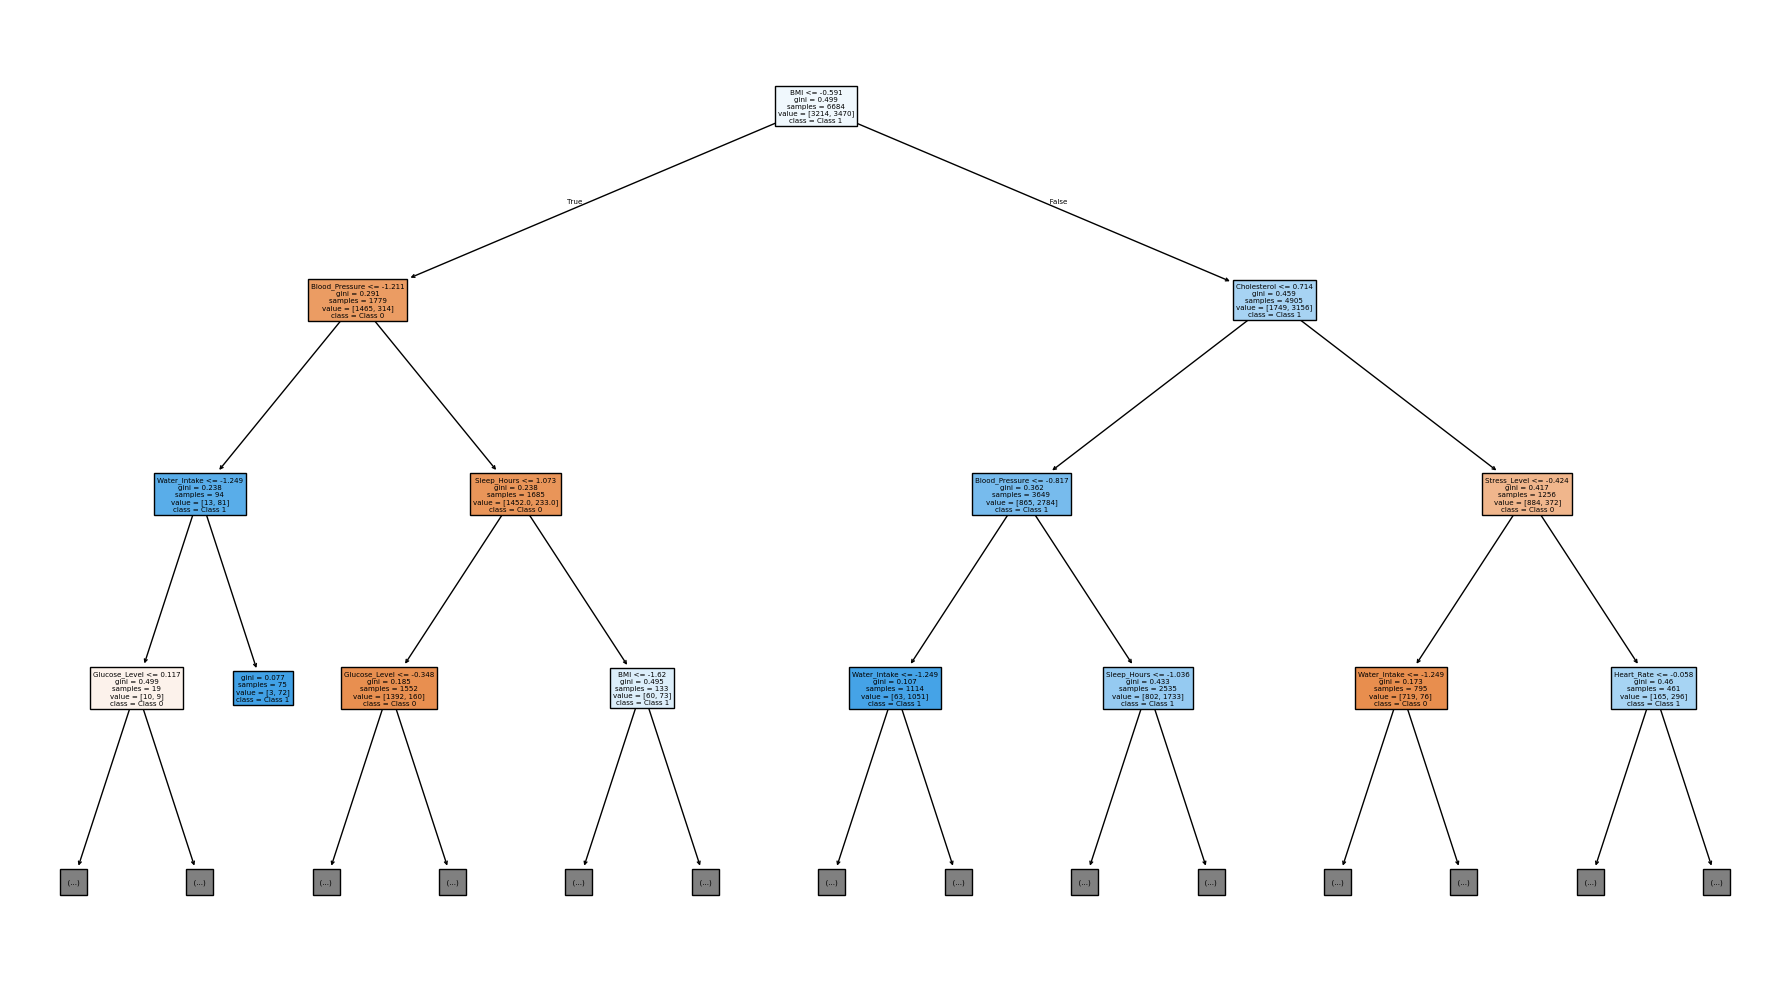

In [76]:
# Decision Tree Classifier Algo

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(x_train,y_train)

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )

# With PrePruninng -> Based on min-sample-split, max-depth, min-sample-leaf

model = model = DecisionTreeClassifier(random_state = 42)

param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_split': [2, 5, 10, 20, 30],
    'min_samples_leaf': [1, 2, 5, 10, 15]
}

grid = GridSearchCV(
    model,
    param_grid,
    scoring = "accuracy",
    cv = 5,
    n_jobs = -1,
    verbose  = 2 # display training progress
)

grid.fit(x_train,y_train)

print("\nBest Parameters:", grid.best_params_)
print("\nBest CV Score:", grid.best_score_)

best_model = grid.best_estimator_  #  retrieves the best-performing model with the optimal hyperparameters found by GridSearchCV. , no need manually again pass best parameter n model and fit 

y_pred = best_model.predict(x_test)

print("\nPre-Prunned-Tree-Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nPre-Prunned-Tree-Recall:", recall_score(y_test,y_pred) )
print("\nPre-Prunned-Tree-Classification-Report:", classification_report(y_test,y_pred) )

# Decision Tree With Post Pruning 

model = DecisionTreeClassifier(random_state=42)

# Generate pruning path
path = model.cost_complexity_pruning_path(x_train, y_train)

# Get candidate alpha values
ccp_alphas = path.ccp_alphas

param_grid = {
    'ccp_alpha': ccp_alphas
}

grid = GridSearchCV(
    model,
    param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("\nBest Alpha:", grid.best_params_)
print("\nBest CV Score:", grid.best_score_)

# Get optimized pruned tree
best_model1 = grid.best_estimator_

# Test prediction
y_pred = best_model1.predict(x_test)

print("\nPost-Prunned-Tree-Accuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nPost-Prunned-Tree-Recall:", recall_score(y_test,y_pred) )
print("\nPost-Prunned-Tree-Classification-Report:", classification_report(y_test,y_pred) )

# Plot Post Prunned Tree 

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18,10))

plot_tree(
    best_model1,
    feature_names=x.columns,
    class_names = ['Class 0', 'Class 1'],
    filled = True,
    max_depth=3
)
plt.tight_layout()
plt.show()



# Ensemble Techniques - Combine multiple model for better Prediction 

# 6. Model - Random Forest (Parallel Process Multiple Decision Tree (Specialized Ensemble Algo))

In [80]:
# Random Forest Algo- Use bootstrapsampling default , Estimator = Decision Tree ,  Process Multiple decision Tree parallel
# It is specialized ensemble Algo
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators = 201,# 100 tree/estimator (default)
    oob_score = True ,  # we use out-of-bag (oob) sample for validation and can access its score

    # default use Bootstrap-Sampling, # max_depth = None default
)

model.fit(x_train,y_train)

y_predict = model.predict(x_test)

print("OOB-Score/Validation-Score:", model.oob_score_ *100)
print("Accuracy-Score:", accuracy_score(y_test,y_predict)*100)

print("\nAccuracy:", accuracy_score(y_test,y_predict) * 100)
print("\nRecall:", recall_score(y_test,y_predict) )
print("\nClassification-Report:", classification_report(y_test,y_predict) )

OOB-Score/Validation-Score: 93.80610412926391
Accuracy-Score: 94.24083769633508

Accuracy: 94.24083769633508

Recall: 0.9516235917826376

Classification-Report:               precision    recall  f1-score   support

           0       0.95      0.93      0.94      1356
           1       0.94      0.95      0.95      1509

    accuracy                           0.94      2865
   macro avg       0.94      0.94      0.94      2865
weighted avg       0.94      0.94      0.94      2865



# 7. Model - Bagging Classifier ( General Ensemble tech. Parellel Process Multiple model (Can use Diff Algo/Models) and Give result Using Aggregate all models Prediction )

In [90]:
# Bagging -> ca use diff base model unlike random forest , General ensemle Algo , Procees Multiple model Parallel

# model = LogisticRegression()  -> we can use all other classification algos 

from sklearn.ensemble import BaggingClassifier

base_model = DecisionTreeClassifier()

bagging = BaggingClassifier(
    base_model,
    n_estimators = 100
)

bagging.fit(x_train,y_train)

y_pred = bagging.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 94.06631762652705

Recall: 0.9390324718356527

Classification-Report:               precision    recall  f1-score   support

           0       0.93      0.94      0.94      1356
           1       0.95      0.94      0.94      1509

    accuracy                           0.94      2865
   macro avg       0.94      0.94      0.94      2865
weighted avg       0.94      0.94      0.94      2865



#  Ensemble technique -> Boosting - Seq. Processing (Enhance performance of model from prev mistakes)

# 8. Gradient Boosting -> Use Residual for improve model

In [96]:
# Gradient Boosting 

from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(
    n_estimators = 200,
    learning_rate = 0.1,
    max_depth = 5, # Gradient Boosting uses Decision Trees internally by default.Therefore, it directly provides max_depth as a parameter.
    random_state = 42
)

gbc.fit(x_train,y_train)

y_pred = gbc.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 94.65968586387434

Recall: 0.953611663353214

Classification-Report:               precision    recall  f1-score   support

           0       0.95      0.94      0.94      1356
           1       0.95      0.95      0.95      1509

    accuracy                           0.95      2865
   macro avg       0.95      0.95      0.95      2865
weighted avg       0.95      0.95      0.95      2865



# 9. AdaBoost -> Use Weights for improve model (Increse weight of wrong predicted samples)

In [110]:
# AdaBoost

from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=5), #AdaBoost uses a Decision Stump (depth = 1) by default in scikit-learn. We can explicitly define the base estimator.
    n_estimators = 200,
    # learning_rate=0.1,
    random_state = 42
)

ada.fit(x_train,y_train)

y_pred = ada.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 94.58987783595113

Recall: 0.949635520212061

Classification-Report:               precision    recall  f1-score   support

           0       0.94      0.94      0.94      1356
           1       0.95      0.95      0.95      1509

    accuracy                           0.95      2865
   macro avg       0.95      0.95      0.95      2865
weighted avg       0.95      0.95      0.95      2865



# 10.  XGBoost - Optimized implementation of Gradient Boosting that uses Additional Regularization and Computational improvements to build powerful models.

In [117]:
# XGBoost 

import xgboost as xgb

xgb_clf = xgb.XGBClassifier(
    n_estimators = 200,
    max_depth = 5,
    learning_rate = 0.1,
    eval_metric = "logloss", # Measures how good predicted probabilities are - used in ->Logistic Regression, Gradient Boosting, XGBoost
    random_state = 42
)

xgb_clf.fit(x_train,y_train)

y_pred = xgb_clf.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 94.86910994764398

Recall: 0.9516235917826376

Classification-Report:               precision    recall  f1-score   support

           0       0.95      0.95      0.95      1356
           1       0.95      0.95      0.95      1509

    accuracy                           0.95      2865
   macro avg       0.95      0.95      0.95      2865
weighted avg       0.95      0.95      0.95      2865



# Ensemble - Heterogeneous

# 11. Voting - Combine Multiple Diff. Models And Predict Based on Final Agrregation 

In [128]:
# Voting 
from sklearn.ensemble import VotingClassifier

lr = LogisticRegression()
svc = SVC()
dtc = DecisionTreeClassifier()
knn = KNeighborsClassifier()
gnb = GaussianNB()
rnf = RandomForestClassifier()

vt_clf = VotingClassifier(
   estimators =  [ ("lr", lr), ("svc", svc), ("dtc", dtc), ("knn", knn), ("gnb", gnb), ("rnf", rnf)]
)

vt_clf.fit(x_train,y_train)


VotingClassifier(estimators=[('lr', LogisticRegression()), ('svc', SVC()),
                             ('dtc', DecisionTreeClassifier()),
                             ('knn', KNeighborsClassifier()),
                             ('gnb', GaussianNB()),
                             ('rnf', RandomForestClassifier())])

In [129]:

y_pred = vt_clf.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 93.19371727748691

Recall: 0.927766732935719

Classification-Report:               precision    recall  f1-score   support

           0       0.92      0.94      0.93      1356
           1       0.94      0.93      0.93      1509

    accuracy                           0.93      2865
   macro avg       0.93      0.93      0.93      2865
weighted avg       0.93      0.93      0.93      2865



# 12. Stacking - Use Multiple Diff Model with diff algo and 1-> Final Model For Predict based on all diif models prediction

In [143]:
# Stacking -> 

from sklearn.ensemble import StackingClassifier

#meta_model = RandomForestClassifier()

lr = LogisticRegression()
svc = SVC()
dtc = DecisionTreeClassifier()
knn = KNeighborsClassifier()
gnb = GaussianNB()
rnf = RandomForestClassifier()

stk_clf = StackingClassifier(
    estimators =  [ ("lr", lr), ("svc", svc), ("dtc", dtc), ("knn", knn), ("gnb", gnb), ("rnf", rnf)] ,  
    cv = 5,
    #final_estimator = meta_model,  # Default (Decision Tree) -> during training of meta model can overfit so we use croos validation
)

stk_clf.fit(x_train,y_train)


StackingClassifier(cv=5,
                   estimators=[('lr', LogisticRegression()), ('svc', SVC()),
                               ('dtc', DecisionTreeClassifier()),
                               ('knn', KNeighborsClassifier()),
                               ('gnb', GaussianNB()),
                               ('rnf', RandomForestClassifier())])

In [144]:
y_pred = stk_clf.predict(x_test)

print("\nAccuracy:", accuracy_score(y_test,y_pred) * 100)
print("\nRecall:", recall_score(y_test,y_pred) )
print("\nClassification-Report:", classification_report(y_test,y_pred) )


Accuracy: 95.11343804537522

Recall: 0.9555997349237906

Classification-Report:               precision    recall  f1-score   support

           0       0.95      0.95      0.95      1356
           1       0.95      0.96      0.95      1509

    accuracy                           0.95      2865
   macro avg       0.95      0.95      0.95      2865
weighted avg       0.95      0.95      0.95      2865

